# Monthly Returns Heatmap (Calendar Table)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

A year × month grid in which every cell is one month's return, colored on a diverging scale centered at zero, with the full-year return in a separate column. It is the standard compact view in fund factsheets: you can read exact numbers and also spot streaks, seasonality and bad years at a glance.

## When to use

- Summarise a multi-year monthly track record on one page
- Look for streaks of losses, seasonality or a change in behavior after a given date
- Give readers exact monthly figures alongside the pattern

## Avoid when

- Fewer than about two years of history (use a bar chart of monthly returns)
- Comparing two funds (use annual returns bars or a difference heatmap)

## Alternatives

- Annual returns bar chart
- Column chart of monthly returns
- Distribution of monthly returns (histogram)

## Design tips

- Use a diverging palette with a neutral midpoint at exactly 0%, symmetric limits
- Keep the annual column visually separate; it is compounded, not a sum of months
- Print values in each cell; switch text to white on dark cells

## Example

Simulated monthly returns for a fund, 2015–2024 (compounded from daily returns). Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

### Data

In [2]:
rng = np.random.default_rng(21)
dates = pd.bdate_range("2015-01-01", "2024-12-31")
n = len(dates)
r = 0.00045 + rng.standard_t(4, n) * 0.0095 / np.sqrt(2)
r[(dates >= "2020-02-20") & (dates <= "2020-03-23")] -= 0.012
r[(dates >= "2022-01-01") & (dates <= "2022-10-15")] -= 0.0011
daily = pd.Series(r, index=dates)
monthly = (1 + daily).resample("ME").prod() - 1   # simple monthly returns
name = "Fund"
monthly.tail()

2024-08-31    0.016541
2024-09-30   -0.007110
2024-10-31   -0.004635
2024-11-30    0.031710
2024-12-31    0.018090
Freq: ME, dtype: float64

### Plot

/var/folders/2q/sq_5xvg16ds08bkpx3ll0pxw0000gn/T/ipykernel_6338/2748841850.py:31: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


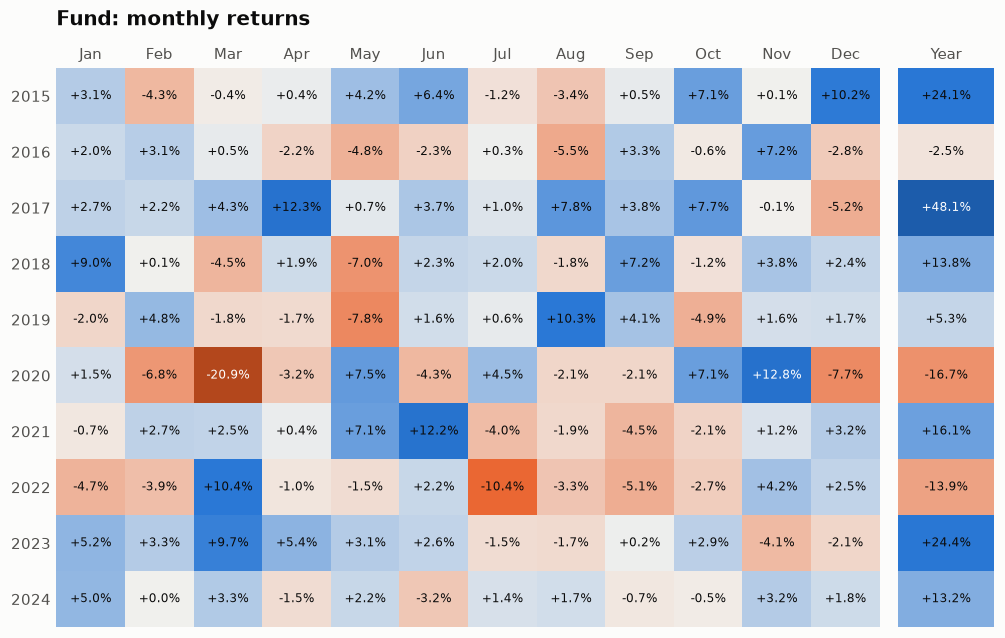

In [3]:
table = pd.DataFrame({"year": monthly.index.year, "month": monthly.index.month, "r": monthly.values})
grid = table.pivot(index="year", columns="month", values="r").reindex(columns=range(1, 13))
annual = table.groupby("year")["r"].apply(lambda x: (1 + x).prod() - 1)

cmap = LinearSegmentedColormap.from_list("loss_gain", ["#b3471c", "#eb6834", "#f2f1ee", "#2a78d6", "#1c5cab"])
lim = np.nanmax(np.abs(grid.values))
fig, (ax, axy) = plt.subplots(1, 2, figsize=(11, 0.5 * len(grid) + 1.6), sharey=True,
                              gridspec_kw={"width_ratios": [12, 1.4], "wspace": 0.04})
ax.imshow(grid.values, cmap=cmap, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
alim = np.abs(annual.values).max()
axy.imshow(annual.values[:, None], cmap=cmap, norm=TwoSlopeNorm(0, -alim, alim), aspect="auto")

def label(axis, values, scale):
    for (i, j), v in np.ndenumerate(values):
        if not np.isnan(v):
            axis.text(j, i, f"{v:+.1%}", ha="center", va="center", fontsize=8,
                      color="white" if abs(v) > 0.6 * scale else "#0b0b0b")

label(ax, grid.values, lim)
label(axy, annual.values[:, None], alim)
ax.set_xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(len(grid)), grid.index)
axy.set_xticks([0], ["Year"])
for a in (ax, axy):
    a.grid(False)
    a.tick_params(length=0)
    for s in a.spines.values():
        s.set_visible(False)
    a.xaxis.tick_top()
ax.set_title(f"{name}: monthly returns", pad=28)
fig.tight_layout()
plt.show()

## How to read it

Blue cells are gaining months and orange cells losing months; stronger color means a bigger move. The right-hand column is the compounded return for each calendar year.

## Try it with real data

**Source:** plotly.express.data.stocks() — MSFT weekly prices resampled to month-end, 2018–2019

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
import plotly.express as px
stocks = px.data.stocks().set_index("date")
px_m = pd.Series(stocks["MSFT"].values, index=pd.to_datetime(stocks.index)).resample("ME").last()
monthly = px_m.pct_change().dropna()
name = "MSFT"
monthly.tail()

date
2019-08-31    0.007012
2019-09-30    0.001886
2019-10-31    0.040544
2019-11-30    0.053298
2019-12-31    0.041749
Freq: ME, dtype: float64

/var/folders/2q/sq_5xvg16ds08bkpx3ll0pxw0000gn/T/ipykernel_6338/2748841850.py:31: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


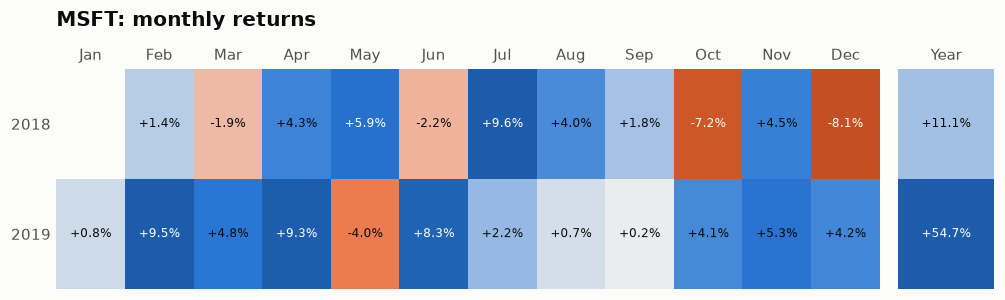

In [5]:
table = pd.DataFrame({"year": monthly.index.year, "month": monthly.index.month, "r": monthly.values})
grid = table.pivot(index="year", columns="month", values="r").reindex(columns=range(1, 13))
annual = table.groupby("year")["r"].apply(lambda x: (1 + x).prod() - 1)

cmap = LinearSegmentedColormap.from_list("loss_gain", ["#b3471c", "#eb6834", "#f2f1ee", "#2a78d6", "#1c5cab"])
lim = np.nanmax(np.abs(grid.values))
fig, (ax, axy) = plt.subplots(1, 2, figsize=(11, 0.5 * len(grid) + 1.6), sharey=True,
                              gridspec_kw={"width_ratios": [12, 1.4], "wspace": 0.04})
ax.imshow(grid.values, cmap=cmap, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
alim = np.abs(annual.values).max()
axy.imshow(annual.values[:, None], cmap=cmap, norm=TwoSlopeNorm(0, -alim, alim), aspect="auto")

def label(axis, values, scale):
    for (i, j), v in np.ndenumerate(values):
        if not np.isnan(v):
            axis.text(j, i, f"{v:+.1%}", ha="center", va="center", fontsize=8,
                      color="white" if abs(v) > 0.6 * scale else "#0b0b0b")

label(ax, grid.values, lim)
label(axy, annual.values[:, None], alim)
ax.set_xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(len(grid)), grid.index)
axy.set_xticks([0], ["Year"])
for a in (ax, axy):
    a.grid(False)
    a.tick_params(length=0)
    for s in a.spines.values():
        s.set_visible(False)
    a.xaxis.tick_top()
ax.set_title(f"{name}: monthly returns", pad=28)
fig.tight_layout()
plt.show()

---
Standalone script: [`monthly_returns_heatmap.py`](monthly_returns_heatmap.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)